In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')
COLORS = {'Safe': '#2ecc71', 'Default': '#e74c3c', 'Accent': '#3498db', 'Warn': '#f39c12'}

# Load processed data
df_loan = pd.read_csv('../dataset/processed/loan_details.csv')
df_customer = pd.read_csv('../dataset/processed/customer_profile.csv')
df_bureau = pd.read_csv('../dataset/processed/bureau_history.csv')
df_risk = pd.read_csv('../dataset/processed/engineered_risk.csv')

df = df_loan.merge(df_customer, on='customer_id')\
            .merge(df_bureau, on='customer_id')\
            .merge(df_risk, on='customer_id')

# Temporal features from raw data
df_raw = pd.read_csv('../dataset/train.csv')
df_raw['DisbursalDate'] = pd.to_datetime(df_raw['DisbursalDate'], format='%d-%m-%y', errors='coerce')
df['Disbursal_Month'] = df_raw['DisbursalDate'].dt.month.values
df['Disbursal_Quarter'] = df_raw['DisbursalDate'].dt.quarter.values
df['Disbursal_MonthName'] = df_raw['DisbursalDate'].dt.month_name().values

print(f"Dataset: {df.shape[0]:,} loans x {df.shape[1]} features")
print(f"Default Rate: {df['loan_default'].mean()*100:.2f}%")
print(f"Total Defaults: {df['loan_default'].sum():,}")
print(f"Total Safe: {(df['loan_default']==0).sum():,}")

c:\Users\bhati\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\bhati\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


Dataset: 233,154 loans x 52 features
Default Rate: 21.71%
Total Defaults: 50,611
Total Safe: 182,543


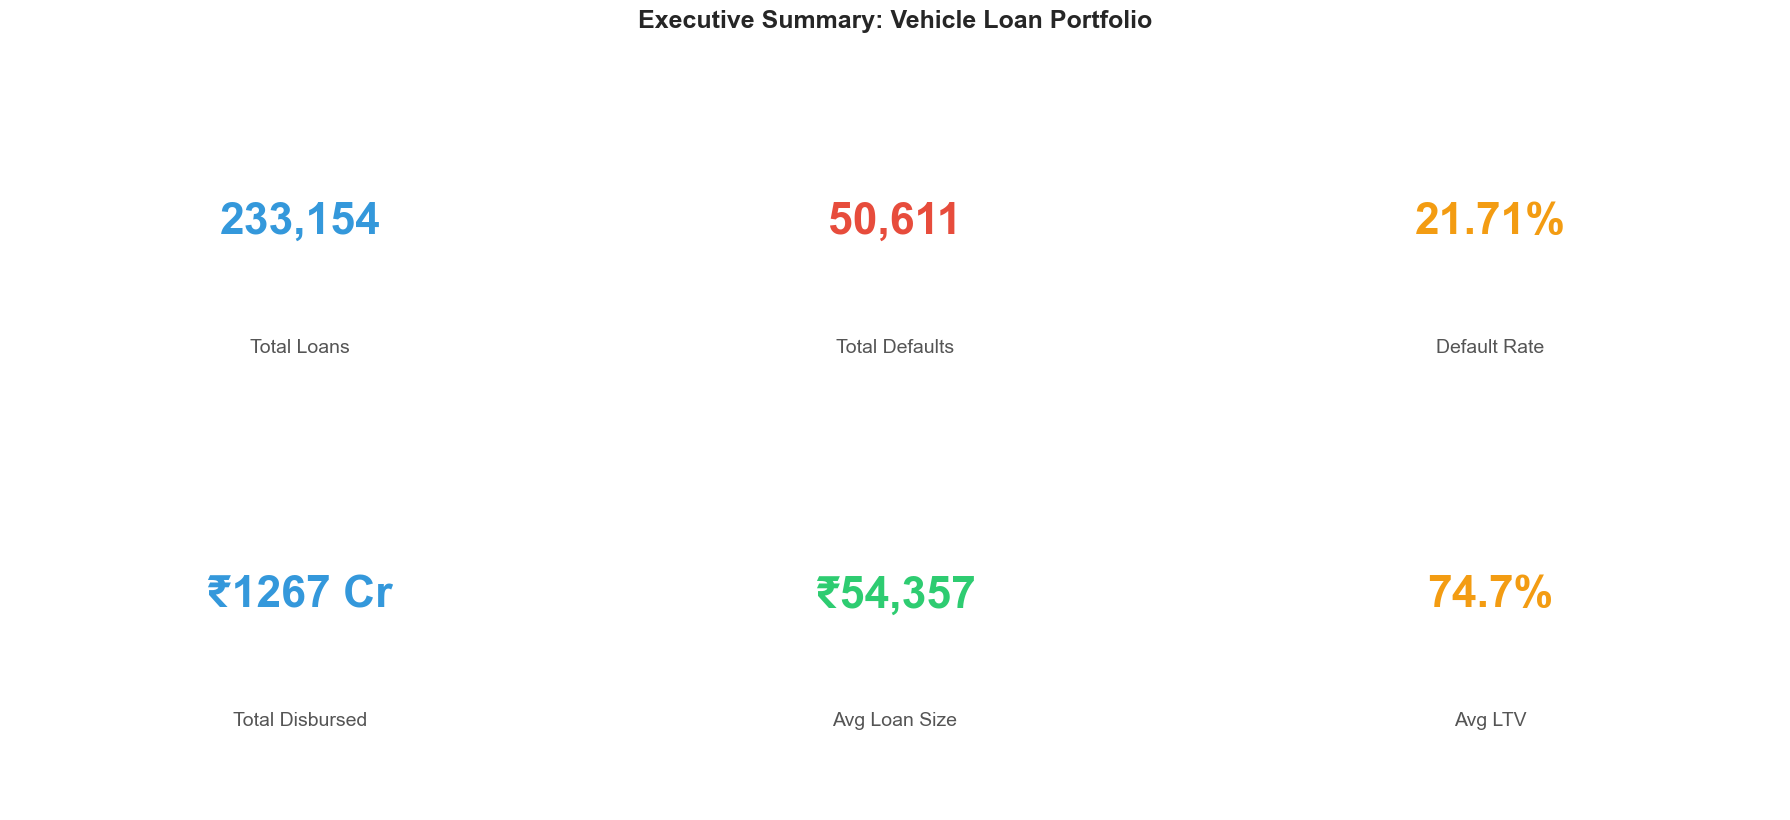

In [2]:
# ================================================================
# PAGE 1: EXECUTIVE SUMMARY KPIs
# ================================================================

total_loans = len(df)
total_defaults = df['loan_default'].sum()
default_rate = df['loan_default'].mean() * 100
total_disbursed = df['disbursed_amount'].sum()
avg_loan = df['disbursed_amount'].mean()
avg_ltv = df['ltv'].mean()

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
fig.suptitle('Executive Summary: Vehicle Loan Portfolio', fontsize=18, fontweight='bold', y=1.02)

kpis = [
    ('Total Loans', f"{total_loans:,}", COLORS['Accent']),
    ('Total Defaults', f"{total_defaults:,}", COLORS['Default']),
    ('Default Rate', f"{default_rate:.2f}%", COLORS['Warn']),
    ('Total Disbursed', f"₹{total_disbursed/1e7:.0f} Cr", COLORS['Accent']),
    ('Avg Loan Size', f"₹{avg_loan:,.0f}", COLORS['Safe']),
    ('Avg LTV', f"{avg_ltv:.1f}%", COLORS['Warn']),
]

for ax, (title, value, color) in zip(axes.flatten(), kpis):
    ax.text(0.5, 0.6, value, ha='center', va='center', fontsize=32, fontweight='bold', color=color, transform=ax.transAxes)
    ax.text(0.5, 0.25, title, ha='center', va='center', fontsize=14, color='#555', transform=ax.transAxes)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.axis('off')
    ax.patch.set_facecolor('#f8f9fa')
    ax.patch.set_edgecolor('#dee2e6')
    ax.patch.set_linewidth(2)

plt.tight_layout()
plt.savefig('../charts/01_executive_kpis.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

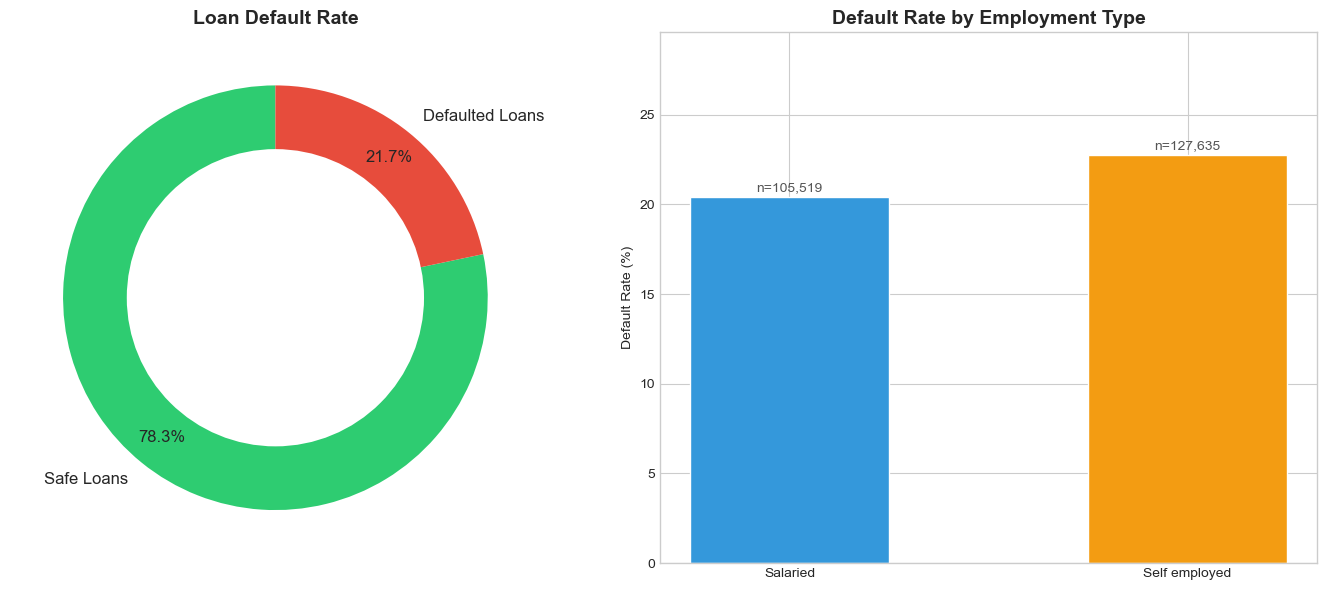

In [3]:
# ================================================================
# CHART 1: Loan Default Distribution (Donut Chart)
# ================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Donut chart
sizes = [total_loans - total_defaults, total_defaults]
labels = ['Safe Loans', 'Defaulted Loans']
colors = [COLORS['Safe'], COLORS['Default']]
wedges, texts, autotexts = ax1.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%',
                                    startangle=90, pctdistance=0.85, textprops={'fontsize': 12})
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
ax1.add_artist(centre_circle)
ax1.set_title('Loan Default Rate', fontsize=14, fontweight='bold')

# Default rate by Employment Type
emp_default = df.groupby('employment_type')['loan_default'].agg(['mean', 'count']).reset_index()
emp_default.columns = ['Employment Type', 'Default Rate', 'Count']
bars = ax2.bar(emp_default['Employment Type'], emp_default['Default Rate'] * 100, 
               color=[COLORS['Accent'], COLORS['Warn']], edgecolor='white', width=0.5)
ax2.set_title('Default Rate by Employment Type', fontsize=14, fontweight='bold')
ax2.set_ylabel('Default Rate (%)')
for bar, count in zip(bars, emp_default['Count']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, 
             f"n={count:,}", ha='center', fontsize=10, color='#555')
ax2.set_ylim(0, max(emp_default['Default Rate'] * 100) * 1.3)

plt.tight_layout()
plt.savefig('../charts/02_default_distribution.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

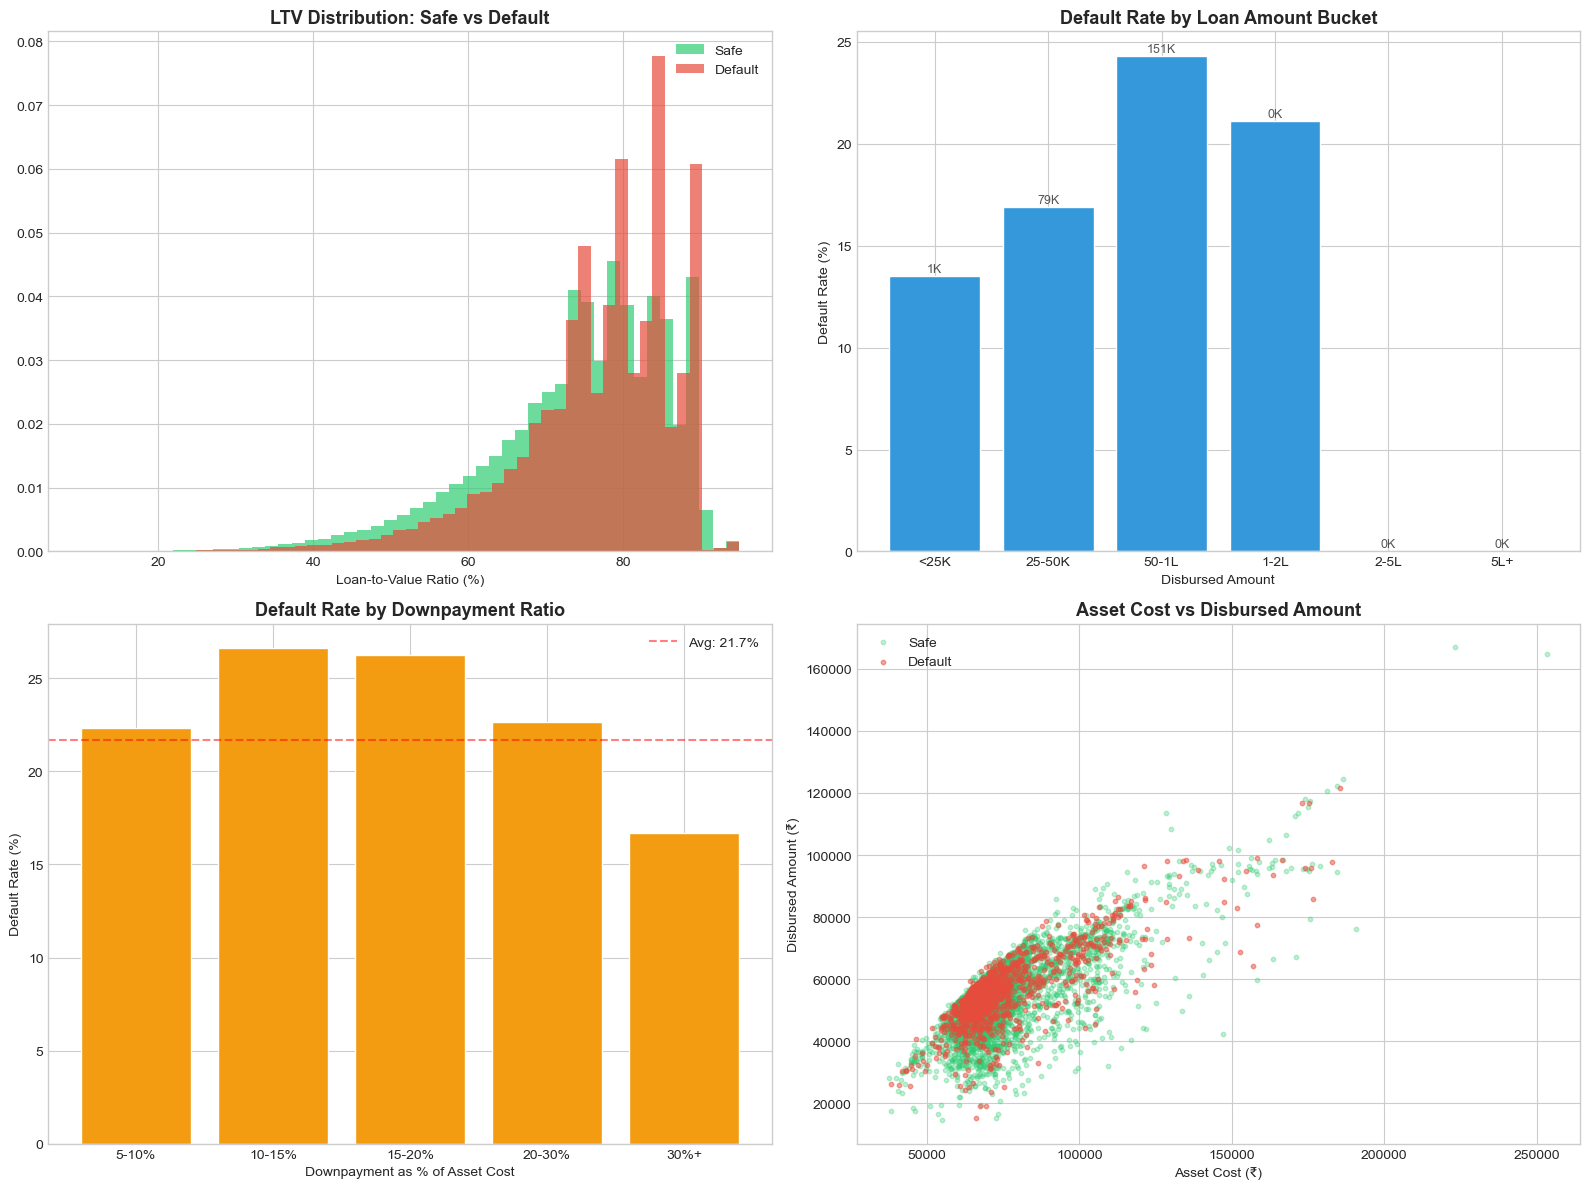

In [4]:
# ================================================================
# PAGE 2: LOAN CHARACTERISTICS ANALYSIS
# ================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Chart 2a: LTV Distribution by Default Status
ax = axes[0, 0]
df[df['loan_default']==0]['ltv'].hist(ax=ax, bins=50, alpha=0.7, color=COLORS['Safe'], label='Safe', density=True)
df[df['loan_default']==1]['ltv'].hist(ax=ax, bins=50, alpha=0.7, color=COLORS['Default'], label='Default', density=True)
ax.set_title('LTV Distribution: Safe vs Default', fontsize=13, fontweight='bold')
ax.set_xlabel('Loan-to-Value Ratio (%)')
ax.legend()

# Chart 2b: Disbursed Amount Distribution
ax = axes[0, 1]
df['disbursed_bucket'] = pd.cut(df['disbursed_amount'], bins=[0, 25000, 50000, 100000, 200000, 500000, np.inf],
                                 labels=['<25K', '25-50K', '50-1L', '1-2L', '2-5L', '5L+'])
bucket_default = df.groupby('disbursed_bucket', observed=True)['loan_default'].agg(['mean', 'count']).reset_index()
bars = ax.bar(bucket_default['disbursed_bucket'], bucket_default['mean'] * 100, 
              color=COLORS['Accent'], edgecolor='white')
ax.set_title('Default Rate by Loan Amount Bucket', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
ax.set_xlabel('Disbursed Amount')
for bar, count in zip(bars, bucket_default['count']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            f"{count//1000}K", ha='center', fontsize=9, color='#555')

# Chart 2c: Downpayment Ratio vs Default
ax = axes[1, 0]
df['dp_bucket'] = pd.cut(df['downpayment_ratio'], bins=[0, 0.05, 0.10, 0.15, 0.20, 0.30, 1.0],
                          labels=['<5%', '5-10%', '10-15%', '15-20%', '20-30%', '30%+'])
dp_default = df.groupby('dp_bucket', observed=True)['loan_default'].mean().reset_index()
bars = ax.bar(dp_default['dp_bucket'], dp_default['loan_default'] * 100, 
              color=COLORS['Warn'], edgecolor='white')
ax.set_title('Default Rate by Downpayment Ratio', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
ax.set_xlabel('Downpayment as % of Asset Cost')
ax.axhline(y=default_rate, color='red', linestyle='--', alpha=0.5, label=f'Avg: {default_rate:.1f}%')
ax.legend()

# Chart 2d: Asset Cost vs Disbursed Amount (Scatter with Default overlay)
ax = axes[1, 1]
sample = df.sample(5000, random_state=42)
ax.scatter(sample[sample['loan_default']==0]['asset_cost'], 
           sample[sample['loan_default']==0]['disbursed_amount'],
           alpha=0.3, s=10, color=COLORS['Safe'], label='Safe')
ax.scatter(sample[sample['loan_default']==1]['asset_cost'], 
           sample[sample['loan_default']==1]['disbursed_amount'],
           alpha=0.5, s=10, color=COLORS['Default'], label='Default')
ax.set_title('Asset Cost vs Disbursed Amount', fontsize=13, fontweight='bold')
ax.set_xlabel('Asset Cost (₹)')
ax.set_ylabel('Disbursed Amount (₹)')
ax.legend()

plt.tight_layout()
plt.savefig('../charts/03_loan_characteristics.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
df.drop(columns=['disbursed_bucket', 'dp_bucket'], inplace=True, errors='ignore')

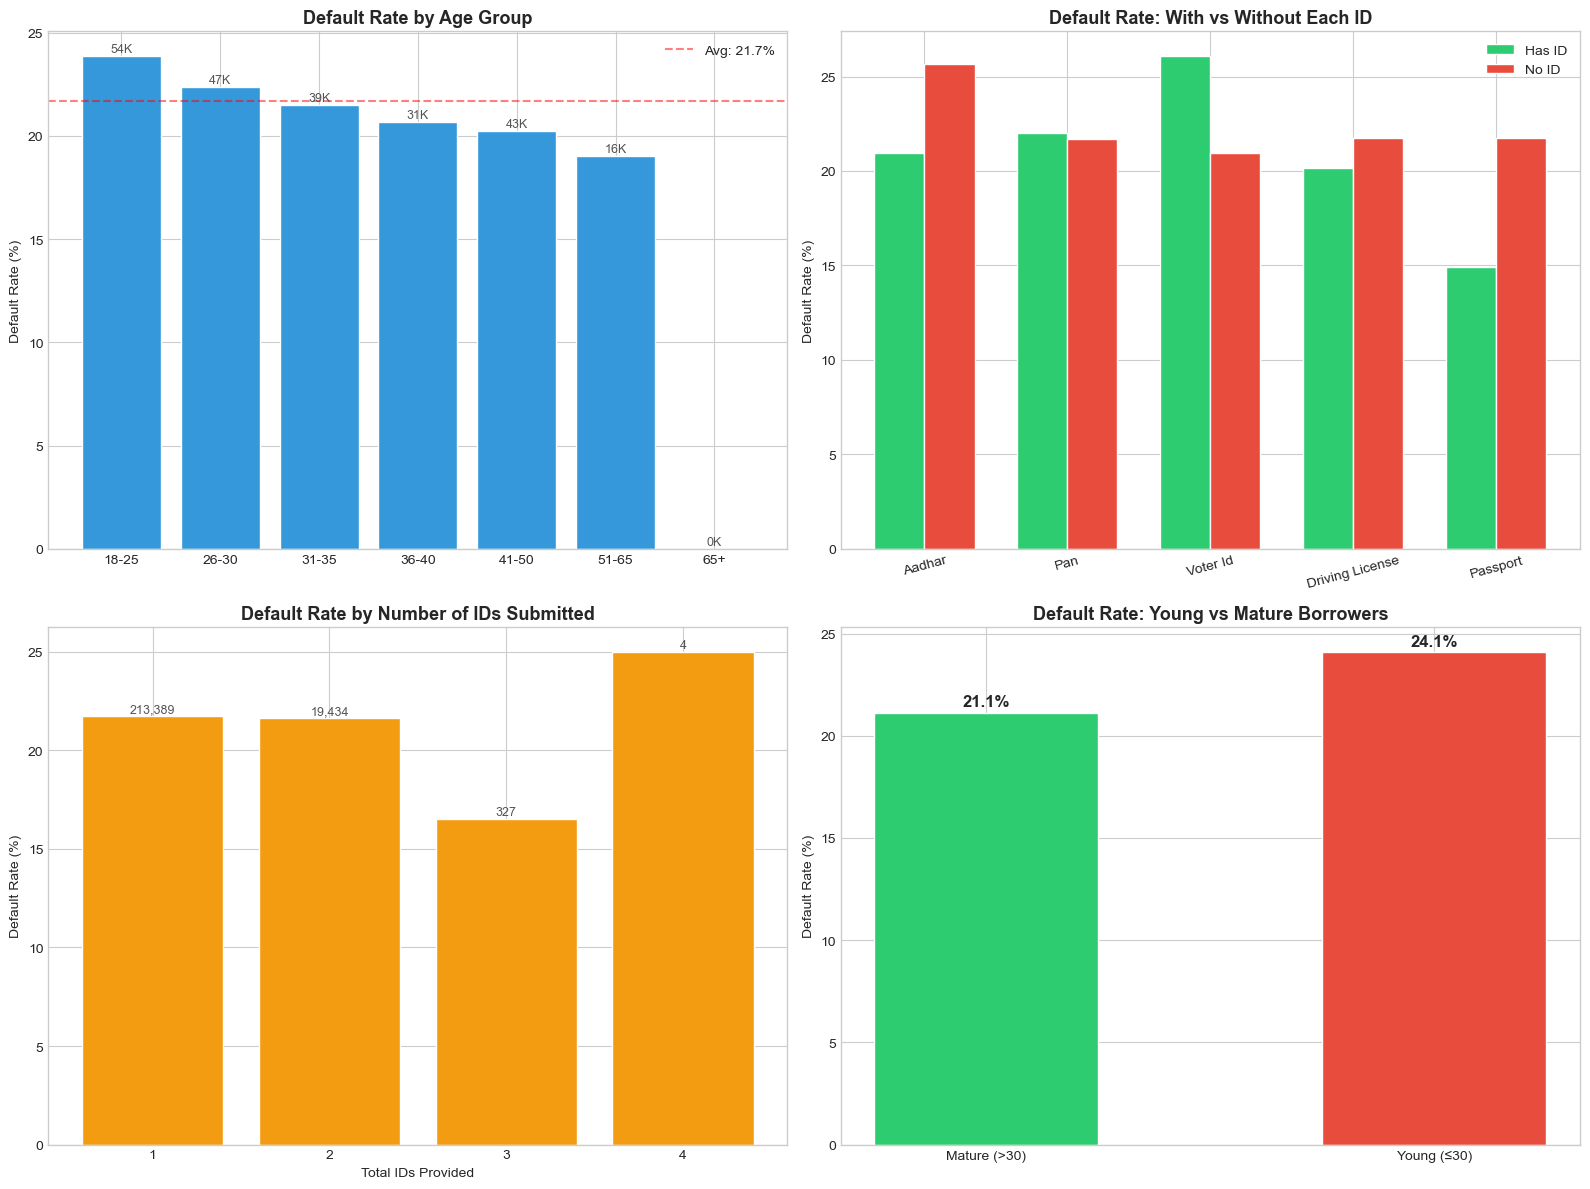

In [5]:
# ================================================================
# PAGE 3: BORROWER DEMOGRAPHICS & RISK PROFILE
# ================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Chart 3a: Age Distribution by Default Status
ax = axes[0, 0]
df['age_bucket'] = pd.cut(df['age_at_disbursal'], bins=[18, 25, 30, 35, 40, 50, 65, 100],
                           labels=['18-25', '26-30', '31-35', '36-40', '41-50', '51-65', '65+'])
age_data = df.groupby('age_bucket', observed=True)['loan_default'].agg(['mean', 'count']).reset_index()
bars = ax.bar(age_data['age_bucket'], age_data['mean'] * 100, color=COLORS['Accent'], edgecolor='white')
ax.set_title('Default Rate by Age Group', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
ax.axhline(y=default_rate, color='red', linestyle='--', alpha=0.5, label=f'Avg: {default_rate:.1f}%')
for bar, count in zip(bars, age_data['count']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            f"{count//1000}K", ha='center', fontsize=9, color='#555')
ax.legend()

# Chart 3b: Identity Documents vs Default Rate
ax = axes[0, 1]
id_cols = ['has_aadhar', 'has_pan', 'has_voter_id', 'has_driving_license', 'has_passport']
id_default = []
for col in id_cols:
    rate_with = df[df[col]==1]['loan_default'].mean() * 100
    rate_without = df[df[col]==0]['loan_default'].mean() * 100
    id_default.append({'ID': col.replace('has_', '').replace('_', ' ').title(), 
                       'With ID': rate_with, 'Without ID': rate_without})
id_df = pd.DataFrame(id_default)
x = np.arange(len(id_df))
w = 0.35
ax.bar(x - w/2, id_df['With ID'], w, label='Has ID', color=COLORS['Safe'], edgecolor='white')
ax.bar(x + w/2, id_df['Without ID'], w, label='No ID', color=COLORS['Default'], edgecolor='white')
ax.set_xticks(x); ax.set_xticklabels(id_df['ID'], rotation=15)
ax.set_title('Default Rate: With vs Without Each ID', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
ax.legend()

# Chart 3c: Total IDs Provided vs Default Rate
ax = axes[1, 0]
ids_data = df.groupby('total_ids_provided')['loan_default'].agg(['mean', 'count']).reset_index()
bars = ax.bar(ids_data['total_ids_provided'].astype(str), ids_data['mean'] * 100, 
              color=COLORS['Warn'], edgecolor='white')
ax.set_title('Default Rate by Number of IDs Submitted', fontsize=13, fontweight='bold')
ax.set_xlabel('Total IDs Provided')
ax.set_ylabel('Default Rate (%)')
for bar, count in zip(bars, ids_data['count']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            f"{count:,}", ha='center', fontsize=9, color='#555')

# Chart 3d: Young Borrower Flag
ax = axes[1, 1]
young_data = df.groupby('is_young_borrower')['loan_default'].mean() * 100
bars = ax.bar(['Mature (>30)', 'Young (≤30)'], young_data.values, 
              color=[COLORS['Safe'], COLORS['Default']], edgecolor='white', width=0.5)
ax.set_title('Default Rate: Young vs Mature Borrowers', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
for bar, val in zip(bars, young_data.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, 
            f"{val:.1f}%", ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('../charts/04_borrower_demographics.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
df.drop(columns=['age_bucket'], inplace=True, errors='ignore')

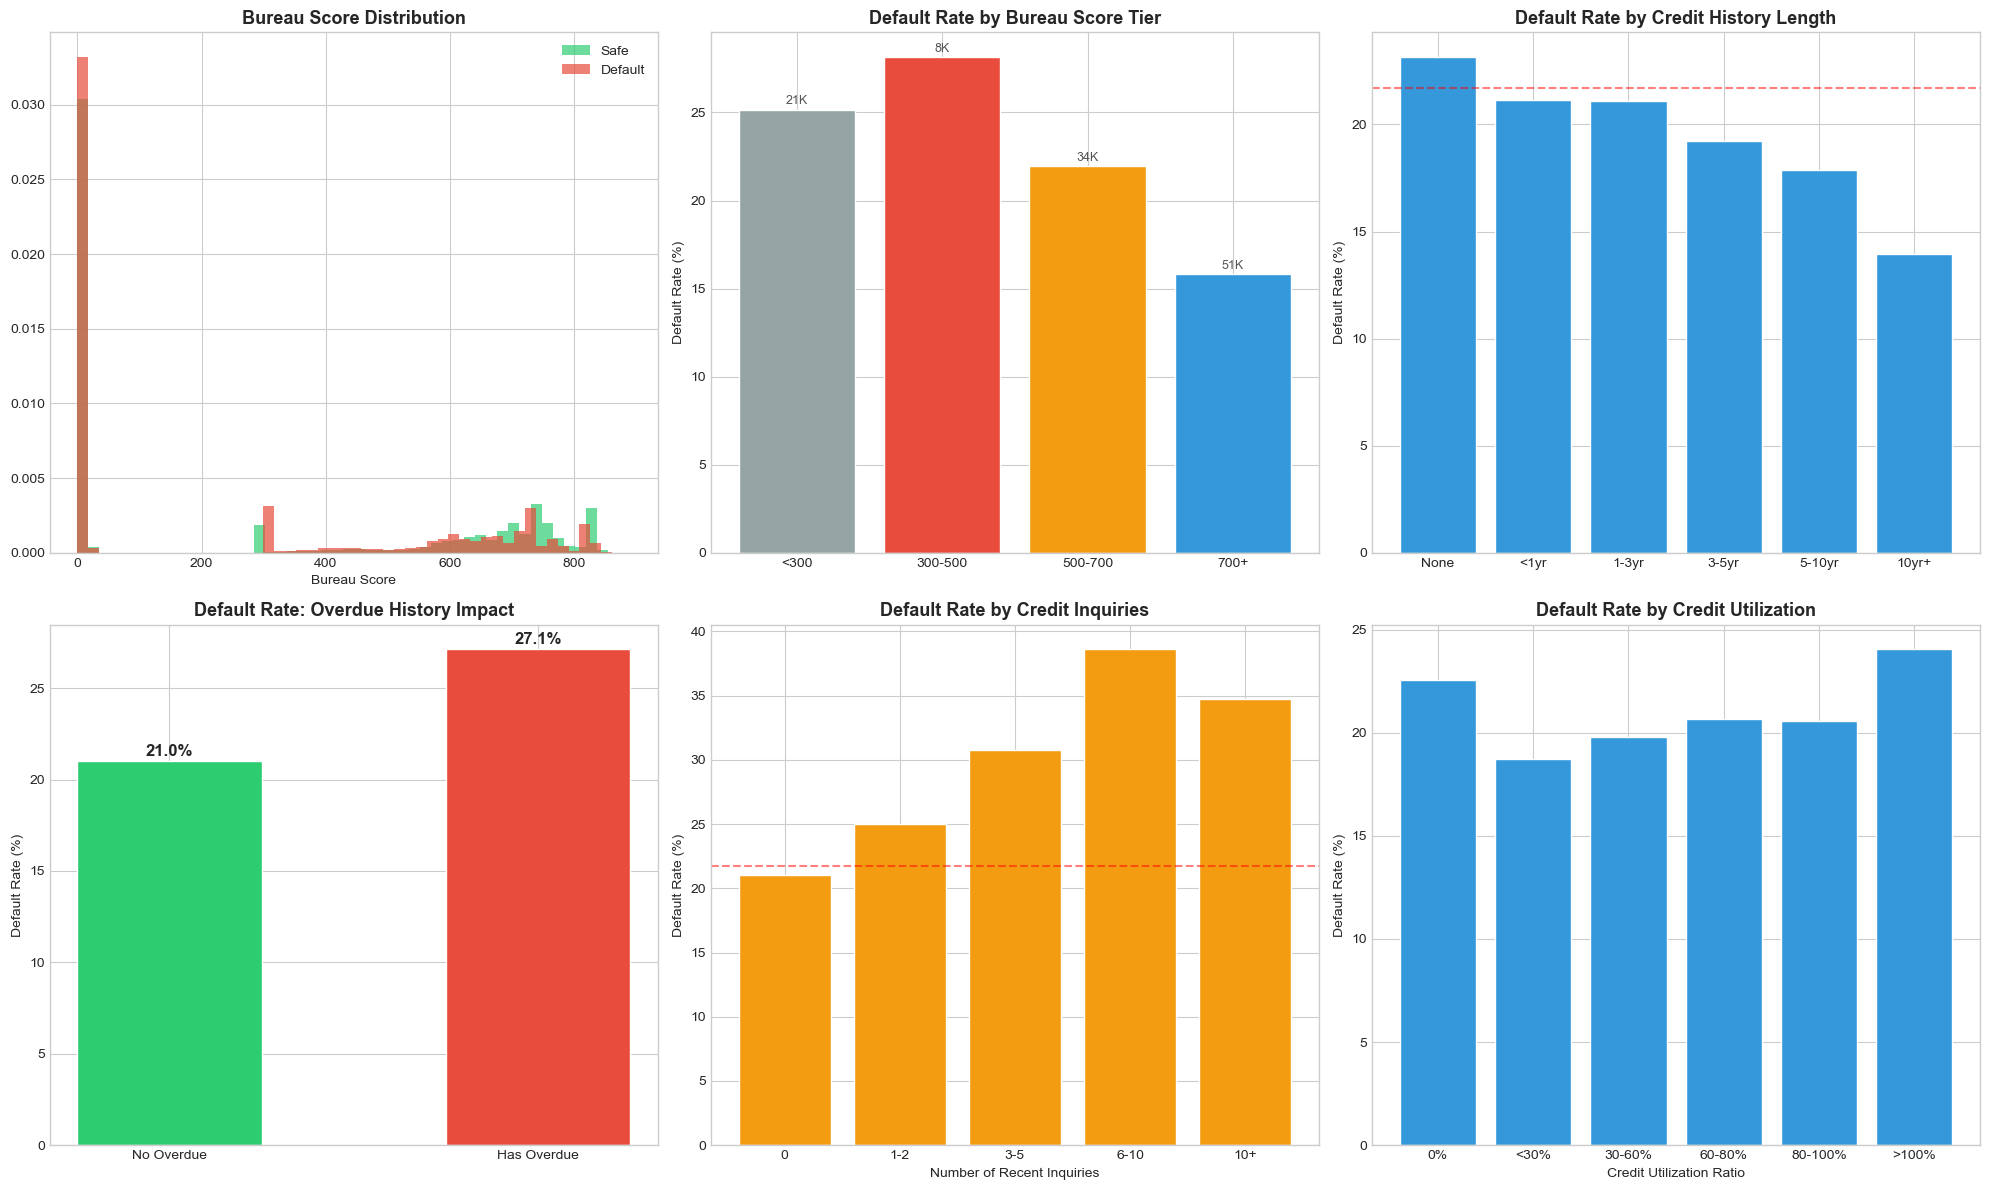

In [6]:
# ================================================================
# PAGE 4: CREDIT BUREAU DEEP DIVE
# ================================================================

fig, axes = plt.subplots(2, 3, figsize=(20, 12))

# Chart 4a: Bureau Score Distribution
ax = axes[0, 0]
df[df['loan_default']==0]['bureau_score'].hist(ax=ax, bins=50, alpha=0.7, color=COLORS['Safe'], label='Safe', density=True)
df[df['loan_default']==1]['bureau_score'].hist(ax=ax, bins=50, alpha=0.7, color=COLORS['Default'], label='Default', density=True)
ax.set_title('Bureau Score Distribution', fontsize=13, fontweight='bold')
ax.set_xlabel('Bureau Score')
ax.legend()

# Chart 4b: Bureau Score Buckets vs Default Rate
ax = axes[0, 1]
df['score_bucket'] = pd.cut(df['bureau_score'], bins=[0, 1, 300, 500, 700, 900], 
                             labels=['No Score', '<300', '300-500', '500-700', '700+'])
score_data = df.groupby('score_bucket', observed=True)['loan_default'].agg(['mean', 'count']).reset_index()
bars = ax.bar(score_data['score_bucket'], score_data['mean'] * 100, 
              color=['#95a5a6', COLORS['Default'], COLORS['Warn'], COLORS['Accent'], COLORS['Safe']], edgecolor='white')
ax.set_title('Default Rate by Bureau Score Tier', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
for bar, count in zip(bars, score_data['count']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f"{count//1000}K", ha='center', fontsize=9, color='#555')

# Chart 4c: Credit History Length vs Default Rate
ax = axes[0, 2]
df['history_bucket'] = pd.cut(df['credit_history_months'], bins=[-1, 0, 12, 36, 60, 120, 500],
                               labels=['None', '<1yr', '1-3yr', '3-5yr', '5-10yr', '10yr+'])
hist_data = df.groupby('history_bucket', observed=True)['loan_default'].mean().reset_index()
ax.bar(hist_data['history_bucket'], hist_data['loan_default'] * 100, color=COLORS['Accent'], edgecolor='white')
ax.set_title('Default Rate by Credit History Length', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
ax.axhline(y=default_rate, color='red', linestyle='--', alpha=0.5)

# Chart 4d: Overdue Accounts vs Default Rate
ax = axes[1, 0]
overdue_data = df.groupby('has_overdue_accounts')['loan_default'].mean() * 100
bars = ax.bar(['No Overdue', 'Has Overdue'], overdue_data.values,
              color=[COLORS['Safe'], COLORS['Default']], edgecolor='white', width=0.5)
ax.set_title('Default Rate: Overdue History Impact', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
for bar, val in zip(bars, overdue_data.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f"{val:.1f}%", ha='center', fontsize=12, fontweight='bold')

# Chart 4e: Inquiry Count vs Default Rate
ax = axes[1, 1]
df['inquiry_bucket'] = pd.cut(df['inquiry_count'], bins=[-1, 0, 2, 5, 10, 100],
                               labels=['0', '1-2', '3-5', '6-10', '10+'])
inq_data = df.groupby('inquiry_bucket', observed=True)['loan_default'].agg(['mean', 'count']).reset_index()
bars = ax.bar(inq_data['inquiry_bucket'], inq_data['mean'] * 100, color=COLORS['Warn'], edgecolor='white')
ax.set_title('Default Rate by Credit Inquiries', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
ax.set_xlabel('Number of Recent Inquiries')
ax.axhline(y=default_rate, color='red', linestyle='--', alpha=0.5)

# Chart 4f: Credit Utilization vs Default Rate
ax = axes[1, 2]
df['util_bucket'] = pd.cut(df['credit_utilization'], bins=[-0.01, 0, 0.3, 0.6, 0.8, 1.0, 100],
                            labels=['0%', '<30%', '30-60%', '60-80%', '80-100%', '>100%'])
util_data = df.groupby('util_bucket', observed=True)['loan_default'].agg(['mean', 'count']).reset_index()
bars = ax.bar(util_data['util_bucket'], util_data['mean'] * 100, color=COLORS['Accent'], edgecolor='white')
ax.set_title('Default Rate by Credit Utilization', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
ax.set_xlabel('Credit Utilization Ratio')

plt.tight_layout()
plt.savefig('../charts/05_credit_bureau.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
df.drop(columns=['score_bucket', 'history_bucket', 'inquiry_bucket', 'util_bucket'], inplace=True, errors='ignore')

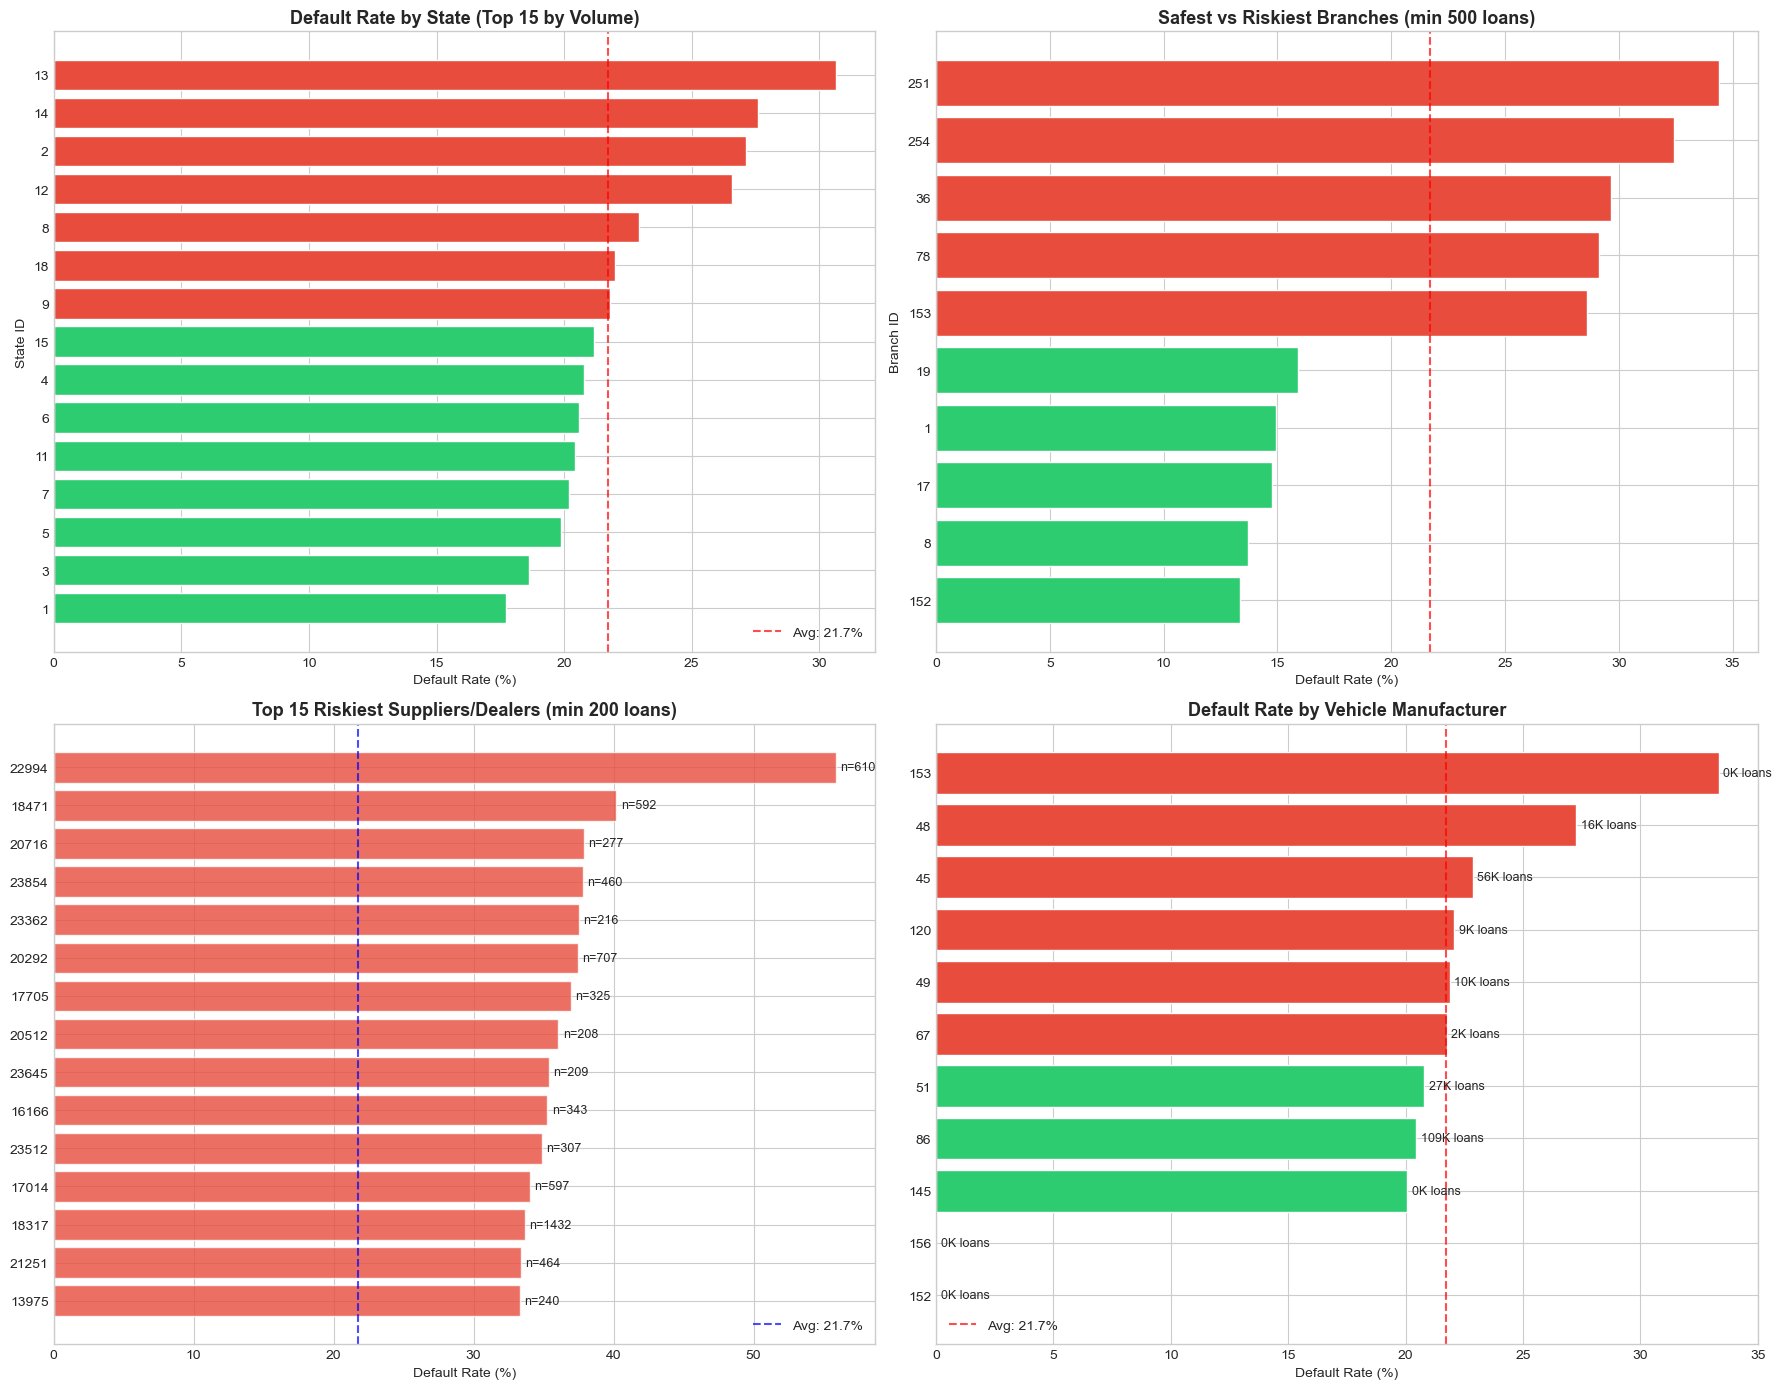

In [7]:
# ================================================================
# PAGE 5: GEOGRAPHIC & OPERATIONAL RISK
# ================================================================

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# Chart 5a: Default Rate by State (Top 15 by volume)
ax = axes[0, 0]
state_data = df.groupby('state_id')['loan_default'].agg(['mean', 'count']).reset_index()
state_data.columns = ['State', 'Default Rate', 'Volume']
state_data = state_data.sort_values('Volume', ascending=False).head(15)
state_data = state_data.sort_values('Default Rate', ascending=True)
colors_state = [COLORS['Default'] if r > default_rate/100 else COLORS['Safe'] for r in state_data['Default Rate']]
bars = ax.barh(state_data['State'].astype(str), state_data['Default Rate'] * 100, color=colors_state, edgecolor='white')
ax.axvline(x=default_rate, color='red', linestyle='--', alpha=0.7, label=f'Avg: {default_rate:.1f}%')
ax.set_title('Default Rate by State (Top 15 by Volume)', fontsize=13, fontweight='bold')
ax.set_xlabel('Default Rate (%)')
ax.set_ylabel('State ID')
ax.legend()

# Chart 5b: Top 10 Riskiest vs Safest Branches
ax = axes[0, 1]
branch_data = df.groupby('branch_id')['loan_default'].agg(['mean', 'count']).reset_index()
branch_data.columns = ['Branch', 'Default Rate', 'Volume']
branch_data = branch_data[branch_data['Volume'] >= 500]  # min 500 loans for reliability
top_risky = branch_data.nlargest(5, 'Default Rate')
top_safe = branch_data.nsmallest(5, 'Default Rate')
combined = pd.concat([top_safe, top_risky]).sort_values('Default Rate')
colors_branch = [COLORS['Default'] if r > default_rate/100 else COLORS['Safe'] for r in combined['Default Rate']]
bars = ax.barh(combined['Branch'].astype(str), combined['Default Rate'] * 100, color=colors_branch, edgecolor='white')
ax.axvline(x=default_rate, color='red', linestyle='--', alpha=0.7)
ax.set_title('Safest vs Riskiest Branches (min 500 loans)', fontsize=13, fontweight='bold')
ax.set_xlabel('Default Rate (%)')
ax.set_ylabel('Branch ID')

# Chart 5c: Top 15 Riskiest Suppliers (min 200 loans)
ax = axes[1, 0]
supplier_data = df.groupby('supplier_id')['loan_default'].agg(['mean', 'count']).reset_index()
supplier_data.columns = ['Supplier', 'Default Rate', 'Volume']
supplier_data = supplier_data[supplier_data['Volume'] >= 200]
top_suppliers = supplier_data.nlargest(15, 'Default Rate').sort_values('Default Rate', ascending=True)
ax.barh(top_suppliers['Supplier'].astype(str), top_suppliers['Default Rate'] * 100, 
        color=COLORS['Default'], edgecolor='white', alpha=0.8)
for i, (_, row) in enumerate(top_suppliers.iterrows()):
    ax.text(row['Default Rate'] * 100 + 0.3, i, f"n={int(row['Volume'])}", va='center', fontsize=9)
ax.axvline(x=default_rate, color='blue', linestyle='--', alpha=0.7, label=f'Avg: {default_rate:.1f}%')
ax.set_title('Top 15 Riskiest Suppliers/Dealers (min 200 loans)', fontsize=13, fontweight='bold')
ax.set_xlabel('Default Rate (%)')
ax.legend()

# Chart 5d: Manufacturer Default Rate
ax = axes[1, 1]
mfg_data = df.groupby('manufacturer_id')['loan_default'].agg(['mean', 'count']).reset_index()
mfg_data.columns = ['Manufacturer', 'Default Rate', 'Volume']
mfg_data = mfg_data.sort_values('Default Rate', ascending=True)
colors_mfg = [COLORS['Default'] if r > default_rate/100 else COLORS['Safe'] for r in mfg_data['Default Rate']]
bars = ax.barh(mfg_data['Manufacturer'].astype(str), mfg_data['Default Rate'] * 100, 
               color=colors_mfg, edgecolor='white')
for i, (_, row) in enumerate(mfg_data.iterrows()):
    ax.text(row['Default Rate'] * 100 + 0.2, i, f"{int(row['Volume'])//1000}K loans", va='center', fontsize=9)
ax.axvline(x=default_rate, color='red', linestyle='--', alpha=0.7, label=f'Avg: {default_rate:.1f}%')
ax.set_title('Default Rate by Vehicle Manufacturer', fontsize=13, fontweight='bold')
ax.set_xlabel('Default Rate (%)')
ax.legend()

plt.tight_layout()
plt.savefig('../charts/06_geographic_operational.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

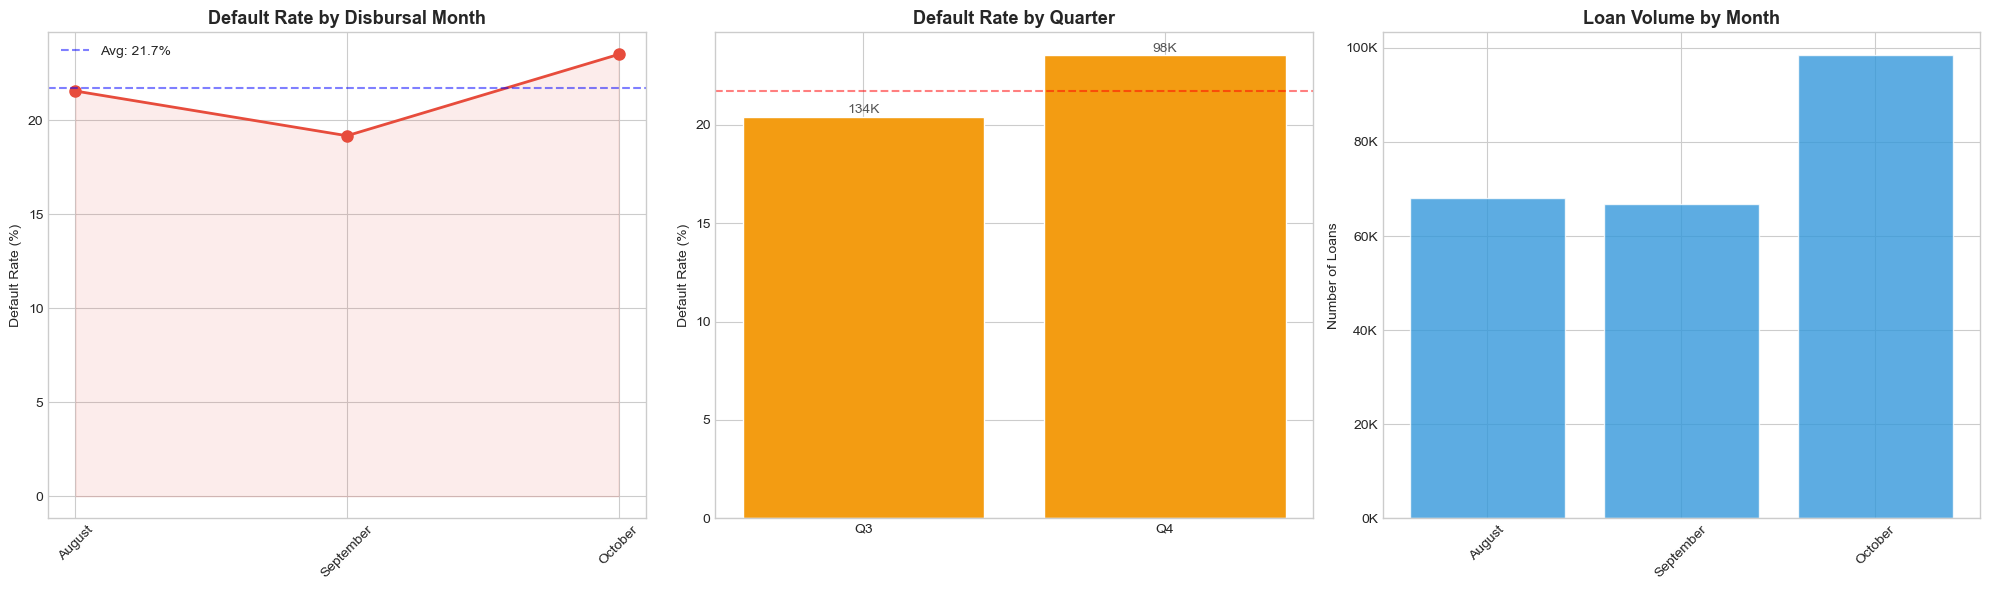

In [8]:
# ================================================================
# PAGE 6: TEMPORAL TRENDS (When do bad loans happen?)
# ================================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Chart 6a: Default Rate by Month
ax = axes[0]
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']
month_data = df.groupby('Disbursal_MonthName')['loan_default'].agg(['mean', 'count']).reset_index()
month_data.columns = ['Month', 'Default Rate', 'Volume']
month_data['Month'] = pd.Categorical(month_data['Month'], categories=month_order, ordered=True)
month_data = month_data.sort_values('Month').dropna(subset=['Month'])
ax.plot(month_data['Month'].astype(str), month_data['Default Rate'] * 100, 
        marker='o', color=COLORS['Default'], linewidth=2, markersize=8)
ax.fill_between(range(len(month_data)), month_data['Default Rate'] * 100, alpha=0.1, color=COLORS['Default'])
ax.axhline(y=default_rate, color='blue', linestyle='--', alpha=0.5, label=f'Avg: {default_rate:.1f}%')
ax.set_title('Default Rate by Disbursal Month', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
ax.tick_params(axis='x', rotation=45)
ax.legend()

# Chart 6b: Default Rate by Quarter
ax = axes[1]
qtr_data = df.groupby('Disbursal_Quarter')['loan_default'].agg(['mean', 'count']).reset_index()
qtr_data.columns = ['Quarter', 'Default Rate', 'Volume']
qtr_data = qtr_data.dropna()
qtr_labels = [f"Q{int(q)}" for q in qtr_data['Quarter']]
bars = ax.bar(qtr_labels, qtr_data['Default Rate'] * 100, color=COLORS['Warn'], edgecolor='white')
ax.set_title('Default Rate by Quarter', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
for bar, vol in zip(bars, qtr_data['Volume']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            f"{int(vol)//1000}K", ha='center', fontsize=10, color='#555')
ax.axhline(y=default_rate, color='red', linestyle='--', alpha=0.5)

# Chart 6c: Loan Volume by Month (Volume Trend)
ax = axes[2]
ax.bar(month_data['Month'].astype(str), month_data['Volume'], color=COLORS['Accent'], edgecolor='white', alpha=0.8)
ax.set_title('Loan Volume by Month', fontsize=13, fontweight='bold')
ax.set_ylabel('Number of Loans')
ax.tick_params(axis='x', rotation=45)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f"{x/1000:.0f}K"))

plt.tight_layout()
plt.savefig('../charts/07_temporal_trends.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

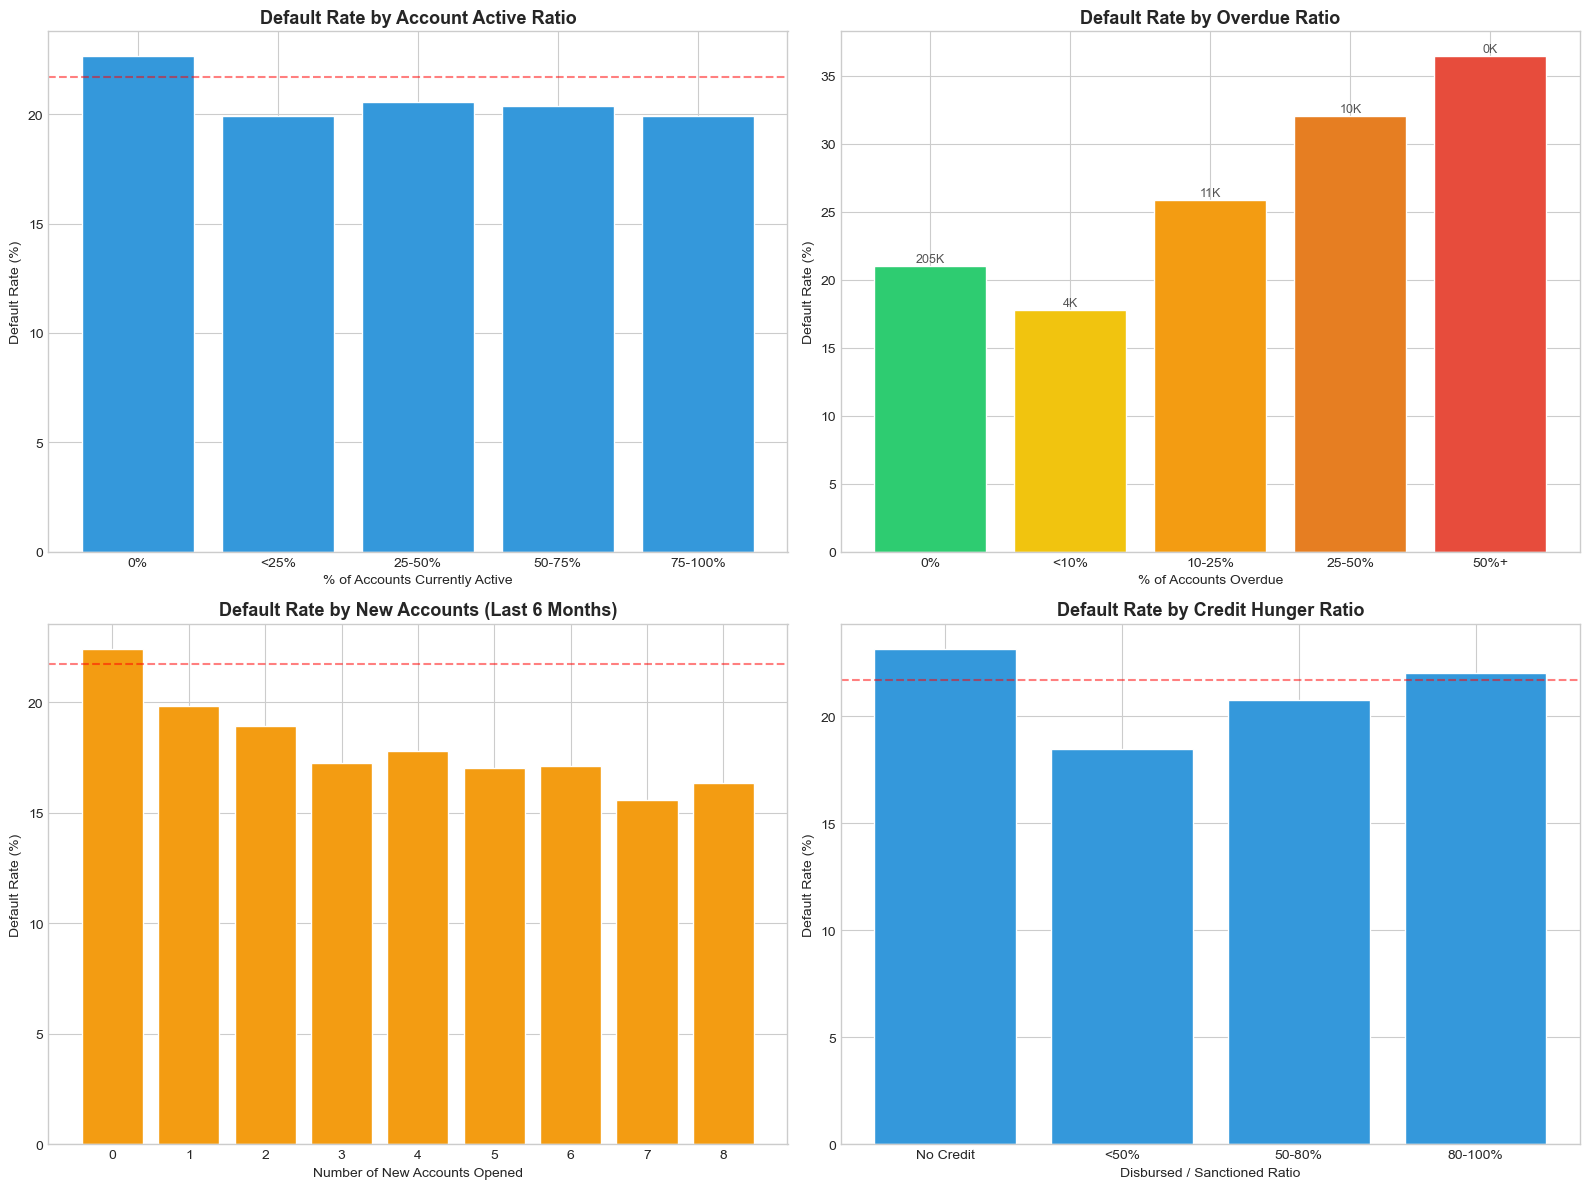

In [9]:
# ================================================================
# PAGE 7: FINANCIAL STRESS INDICATORS
# ================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Chart 7a: Active Ratio Distribution by Default Status
ax = axes[0, 0]
df['active_bucket'] = pd.cut(df['active_ratio'], bins=[-0.01, 0, 0.25, 0.5, 0.75, 1.0],
                              labels=['0%', '<25%', '25-50%', '50-75%', '75-100%'])
ar_data = df.groupby('active_bucket', observed=True)['loan_default'].agg(['mean', 'count']).reset_index()
bars = ax.bar(ar_data['active_bucket'], ar_data['mean'] * 100, color=COLORS['Accent'], edgecolor='white')
ax.set_title('Default Rate by Account Active Ratio', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
ax.set_xlabel('% of Accounts Currently Active')
ax.axhline(y=default_rate, color='red', linestyle='--', alpha=0.5)

# Chart 7b: Overdue Ratio Distribution
ax = axes[0, 1]
df['overdue_bucket'] = pd.cut(df['overdue_ratio'], bins=[-0.01, 0, 0.1, 0.25, 0.5, 1.0],
                               labels=['0%', '<10%', '10-25%', '25-50%', '50%+'])
or_data = df.groupby('overdue_bucket', observed=True)['loan_default'].agg(['mean', 'count']).reset_index()
bars = ax.bar(or_data['overdue_bucket'], or_data['mean'] * 100, 
              color=[COLORS['Safe'], '#f1c40f', COLORS['Warn'], '#e67e22', COLORS['Default']], edgecolor='white')
ax.set_title('Default Rate by Overdue Ratio', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
ax.set_xlabel('% of Accounts Overdue')
for bar, count in zip(bars, or_data['count']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f"{count//1000}K", ha='center', fontsize=9, color='#555')

# Chart 7c: New Accounts in Last 6 Months vs Default
ax = axes[1, 0]
new_data = df.groupby('new_accounts_6m')['loan_default'].agg(['mean', 'count']).reset_index()
new_data = new_data[new_data['count'] >= 100]
ax.bar(new_data['new_accounts_6m'].astype(str), new_data['mean'] * 100, color=COLORS['Warn'], edgecolor='white')
ax.set_title('Default Rate by New Accounts (Last 6 Months)', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
ax.set_xlabel('Number of New Accounts Opened')
ax.axhline(y=default_rate, color='red', linestyle='--', alpha=0.5)

# Chart 7d: Credit Hunger Ratio Distribution
ax = axes[1, 1]
df['hunger_bucket'] = pd.cut(df['credit_hunger_ratio'], bins=[-0.01, 0, 0.5, 0.8, 1.0, 100],
                              labels=['No Credit', '<50%', '50-80%', '80-100%', '>100%'])
hunger_data = df.groupby('hunger_bucket', observed=True)['loan_default'].agg(['mean', 'count']).reset_index()
bars = ax.bar(hunger_data['hunger_bucket'], hunger_data['mean'] * 100, color=COLORS['Accent'], edgecolor='white')
ax.set_title('Default Rate by Credit Hunger Ratio', fontsize=13, fontweight='bold')
ax.set_ylabel('Default Rate (%)')
ax.set_xlabel('Disbursed / Sanctioned Ratio')
ax.axhline(y=default_rate, color='red', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../charts/08_financial_stress.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
df.drop(columns=['active_bucket', 'overdue_bucket', 'hunger_bucket'], inplace=True, errors='ignore')

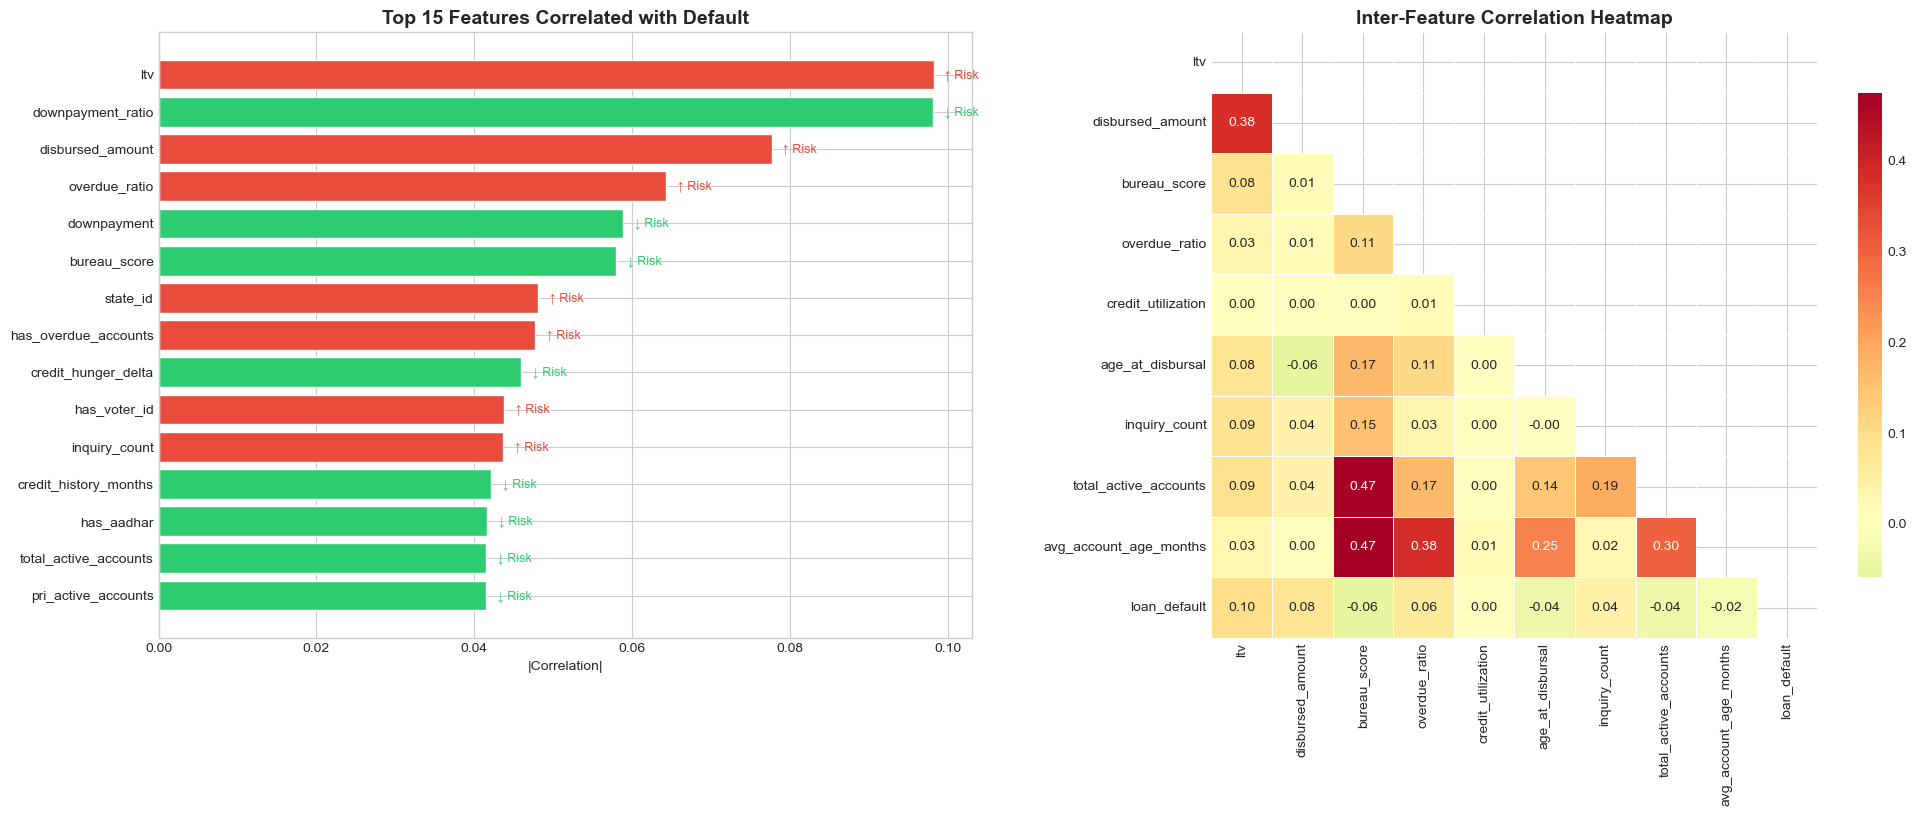

In [10]:
# ================================================================
# PAGE 8: FEATURE CORRELATION WITH DEFAULT
# ================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

# Chart 8a: Top 15 Features Correlated with Default
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_target = df[numeric_cols].corr()['loan_default'].drop(['loan_default', 'customer_id'], errors='ignore')
top_corr = corr_target.abs().sort_values(ascending=False).head(15)
colors_corr = [COLORS['Default'] if corr_target[col] > 0 else COLORS['Safe'] for col in top_corr.index]
bars = ax1.barh(range(len(top_corr)), top_corr.values, color=colors_corr, edgecolor='white')
ax1.set_yticks(range(len(top_corr)))
ax1.set_yticklabels(top_corr.index, fontsize=10)
ax1.set_title('Top 15 Features Correlated with Default', fontsize=14, fontweight='bold')
ax1.set_xlabel('|Correlation|')
ax1.invert_yaxis()
# Add direction labels
for i, col in enumerate(top_corr.index):
    direction = '↑ Risk' if corr_target[col] > 0 else '↓ Risk'
    ax1.text(top_corr.values[i] + 0.001, i, f" {direction}", va='center', fontsize=9, 
             color=COLORS['Default'] if corr_target[col] > 0 else COLORS['Safe'])

# Chart 8b: Heatmap of top features inter-correlation
top_features = ['ltv', 'disbursed_amount', 'bureau_score', 'overdue_ratio', 
                'credit_utilization', 'age_at_disbursal', 'inquiry_count',
                'total_active_accounts', 'avg_account_age_months', 'loan_default']
corr_matrix = df[top_features].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn_r', center=0,
            ax=ax2, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
ax2.set_title('Inter-Feature Correlation Heatmap', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../charts/09_correlations.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

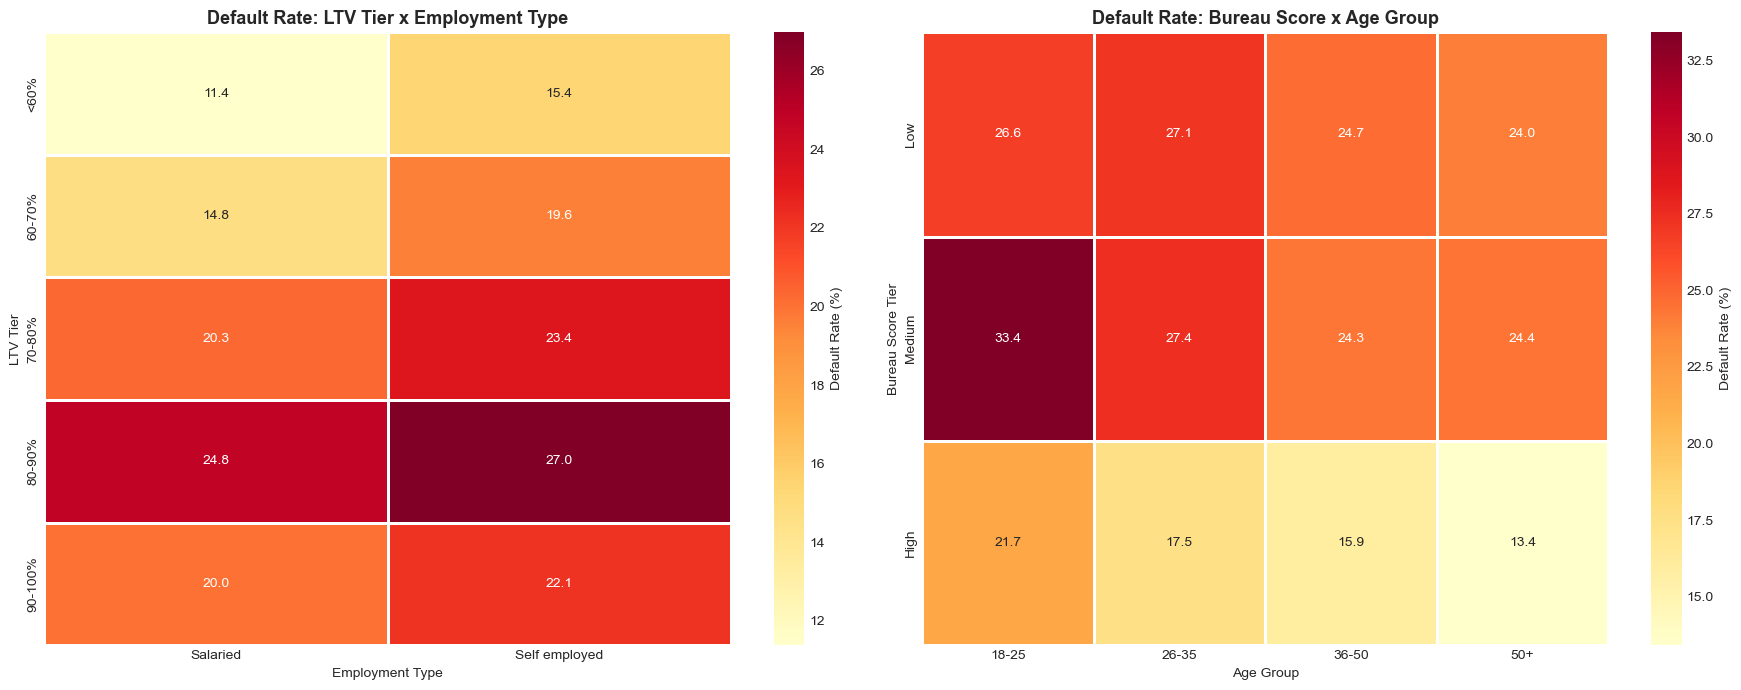

In [11]:
# ================================================================
# PAGE 9: RISK SEGMENTATION MATRIX
# ================================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Chart 9a: LTV Bucket x Employment Type Heatmap
ax = axes[0]
df['ltv_tier'] = pd.cut(df['ltv'], bins=[0, 60, 70, 80, 90, 100], 
                         labels=['<60%', '60-70%', '70-80%', '80-90%', '90-100%'])
pivot1 = df.pivot_table(values='loan_default', index='ltv_tier', columns='employment_type', aggfunc='mean') * 100
sns.heatmap(pivot1, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax, linewidths=1, 
            cbar_kws={'label': 'Default Rate (%)'})
ax.set_title('Default Rate: LTV Tier x Employment Type', fontsize=13, fontweight='bold')
ax.set_ylabel('LTV Tier')
ax.set_xlabel('Employment Type')

# Chart 9b: Bureau Score Tier x Age Group Heatmap
ax = axes[1]
df['score_tier'] = pd.cut(df['bureau_score'], bins=[0, 1, 400, 600, 900],
                           labels=['No Score', 'Low', 'Medium', 'High'])
df['age_tier'] = pd.cut(df['age_at_disbursal'], bins=[18, 25, 35, 50, 100],
                         labels=['18-25', '26-35', '36-50', '50+'])
pivot2 = df.pivot_table(values='loan_default', index='score_tier', columns='age_tier', aggfunc='mean') * 100
sns.heatmap(pivot2, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax, linewidths=1,
            cbar_kws={'label': 'Default Rate (%)'})
ax.set_title('Default Rate: Bureau Score x Age Group', fontsize=13, fontweight='bold')
ax.set_ylabel('Bureau Score Tier')
ax.set_xlabel('Age Group')

plt.tight_layout()
plt.savefig('../charts/10_risk_segmentation.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
df.drop(columns=['ltv_tier', 'score_tier', 'age_tier'], inplace=True, errors='ignore')

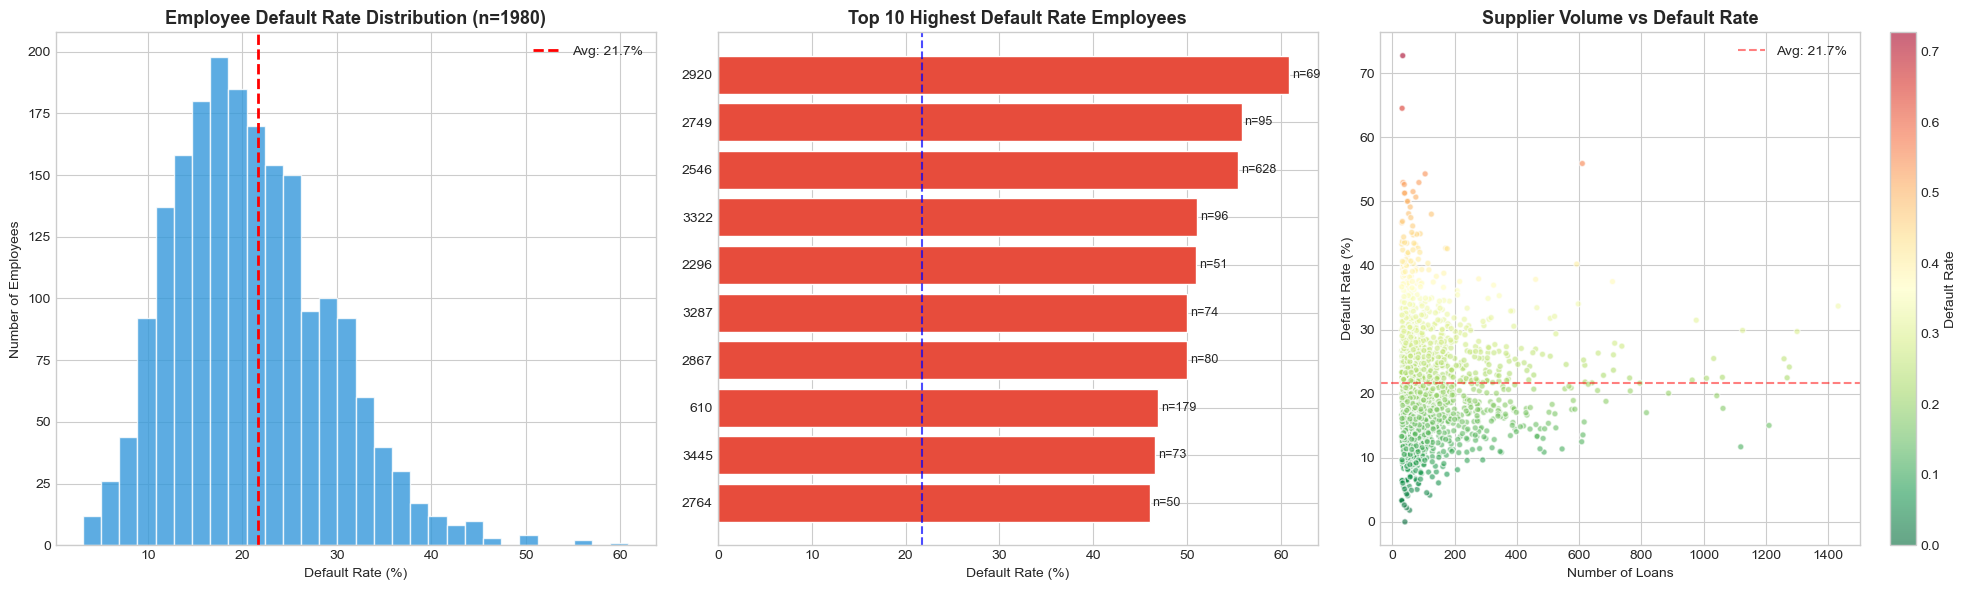

In [12]:
# ================================================================
# PAGE 10: EMPLOYEE & DEALER PERFORMANCE
# ================================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Chart 10a: Employee Performance Distribution
ax = axes[0]
emp_data = df.groupby('employee_id')['loan_default'].agg(['mean', 'count']).reset_index()
emp_data.columns = ['Employee', 'Default Rate', 'Loans Processed']
emp_data = emp_data[emp_data['Loans Processed'] >= 50]
ax.hist(emp_data['Default Rate'] * 100, bins=30, color=COLORS['Accent'], edgecolor='white', alpha=0.8)
ax.axvline(x=default_rate, color='red', linestyle='--', linewidth=2, label=f'Avg: {default_rate:.1f}%')
ax.set_title(f'Employee Default Rate Distribution (n={len(emp_data)})', fontsize=13, fontweight='bold')
ax.set_xlabel('Default Rate (%)')
ax.set_ylabel('Number of Employees')
ax.legend()

# Chart 10b: Top 10 Worst Employees
ax = axes[1]
worst_emp = emp_data.nlargest(10, 'Default Rate').sort_values('Default Rate', ascending=True)
ax.barh(worst_emp['Employee'].astype(str), worst_emp['Default Rate'] * 100, color=COLORS['Default'], edgecolor='white')
for i, (_, row) in enumerate(worst_emp.iterrows()):
    ax.text(row['Default Rate'] * 100 + 0.3, i, f"n={int(row['Loans Processed'])}", va='center', fontsize=9)
ax.axvline(x=default_rate, color='blue', linestyle='--', alpha=0.7)
ax.set_title('Top 10 Highest Default Rate Employees', fontsize=13, fontweight='bold')
ax.set_xlabel('Default Rate (%)')

# Chart 10c: Loan Volume vs Default Rate (Scatter for Suppliers)
ax = axes[2]
supplier_data = df.groupby('supplier_id')['loan_default'].agg(['mean', 'count']).reset_index()
supplier_data.columns = ['Supplier', 'Default Rate', 'Volume']
supplier_data = supplier_data[supplier_data['Volume'] >= 30]
scatter = ax.scatter(supplier_data['Volume'], supplier_data['Default Rate'] * 100, 
                     c=supplier_data['Default Rate'], cmap='RdYlGn_r', s=20, alpha=0.6, edgecolors='white')
ax.axhline(y=default_rate, color='red', linestyle='--', alpha=0.5, label=f'Avg: {default_rate:.1f}%')
ax.set_title('Supplier Volume vs Default Rate', fontsize=13, fontweight='bold')
ax.set_xlabel('Number of Loans')
ax.set_ylabel('Default Rate (%)')
ax.legend()
plt.colorbar(scatter, ax=ax, label='Default Rate')

plt.tight_layout()
plt.savefig('../charts/11_employee_dealer.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

In [13]:
# ================================================================
# DASHBOARD STORY SUMMARY
# ================================================================

print("=" * 80)
print(" VEHICLE LOAN DEFAULT: THE DATA STORY")
print("=" * 80)

print("""
📊 THE BIG PICTURE:
   • Out of {total:,} vehicle loans, {defaults:,} defaulted ({rate:.1f}%)
   • Total portfolio value: ₹{value:.0f} Crore

👤 WHO DEFAULTS?
   • Young borrowers (≤30) default MORE than mature borrowers
   • Self-employed borrowers are riskier than salaried ones
   • Borrowers with fewer identity documents are riskier
   • Borrowers with NO credit history have the highest default rate

💰 LOAN RED FLAGS:
   • Higher LTV (>85%) = significantly higher default rate
   • Lower downpayment ratio = higher default rate
   • Larger loan amounts correlate with higher defaults

📋 CREDIT BUREAU SIGNALS:
   • Borrowers with overdue accounts are 2-3x more likely to default
   • Higher inquiry counts = credit hunger = higher default
   • Short credit history (<1 year) = elevated risk
   • Low bureau scores (<300) have the worst default rates

🏢 OPERATIONAL RISK:
   • Certain suppliers/dealers have 2-3x the average default rate
   • Specific employees consistently process more bad loans
   • Some states have structurally higher default rates
   • Certain manufacturers carry higher risk profiles

📅 TEMPORAL PATTERNS:
   • Default rates vary by quarter and month
   • End-of-period (quarter/month) loan pushes may carry higher risk

🎯 KEY INSIGHT FOR POWERBI DASHBOARD:
   The default story is NOT just about bad borrowers. It's a systemic issue 
   across GEOGRAPHY (certain states/pincodes), OPERATIONS (certain dealers & 
   employees), and TIMING (certain months). A comprehensive risk dashboard 
   must track ALL three dimensions simultaneously.
""".format(
    total=total_loans,
    defaults=total_defaults,
    rate=default_rate,
    value=total_disbursed/1e7
))

 VEHICLE LOAN DEFAULT: THE DATA STORY

📊 THE BIG PICTURE:
   • Out of 233,154 vehicle loans, 50,611 defaulted (21.7%)
   • Total portfolio value: ₹1267 Crore

👤 WHO DEFAULTS?
   • Young borrowers (≤30) default MORE than mature borrowers
   • Self-employed borrowers are riskier than salaried ones
   • Borrowers with fewer identity documents are riskier
   • Borrowers with NO credit history have the highest default rate

💰 LOAN RED FLAGS:
   • Higher LTV (>85%) = significantly higher default rate
   • Lower downpayment ratio = higher default rate
   • Larger loan amounts correlate with higher defaults

📋 CREDIT BUREAU SIGNALS:
   • Borrowers with overdue accounts are 2-3x more likely to default
   • Higher inquiry counts = credit hunger = higher default
   • Short credit history (<1 year) = elevated risk
   • Low bureau scores (<300) have the worst default rates

🏢 OPERATIONAL RISK:
   • Certain suppliers/dealers have 2-3x the average default rate
   • Specific employees consistently pro